In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("mymoviedb.csv",engine='python')
df_clean = df.copy()
print(f"Load dataset: {df_clean.shape[0]} and row : {df_clean.shape[1]}")


Load dataset: 9837 and row : 9


In [5]:
#view some rows 
df_clean.head(2);
df_clean.tail(2);
df_clean.sample(1)

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
1158,2021-09-22,We Are Nothing,"La Polla Records, one of the most legendary pu...",59.824,3,3.5,es,"Documentary, Music",https://image.tmdb.org/t/p/original/nRF7RpfFUT...


In [6]:
# explor dataset structure 

df_clean.shape;
df_clean.columns.to_list();
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   str    
 1   Title              9828 non-null   str    
 2   Overview           9828 non-null   str    
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   str    
 5   Vote_Average       9827 non-null   str    
 6   Original_Language  9827 non-null   str    
 7   Genre              9826 non-null   str    
 8   Poster_Url         9826 non-null   str    
dtypes: float64(1), str(8)
memory usage: 4.5 MB


In [7]:
# Find missing value 
df_clean.isnull().sum()

Release_Date          0
Title                 9
Overview              9
Popularity           10
Vote_Count           10
Vote_Average         10
Original_Language    10
Genre                11
Poster_Url           11
dtype: int64

In [8]:
# Explor duplicate value 
df_clean.duplicated().sum() 

np.int64(0)

In [9]:
# Explor numerical col
df_clean.describe()

,Popularity
count,9827.000000
mean,40.320570
std,108.874308
min,7.100000
25%,16.127500
50%,21.191000
75%,35.174500
max,5083.954000


In [10]:
# Explor catagorial col
df_clean['Genre'].value_counts()
df_clean['Genre'].unique()
df_clean['Genre'].nunique()

2337

In [11]:
df_clean.sample(3)

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
7432,2012-09-20,Amour,Georges and Anne are in their eighties. They a...,16.052,1272,7.8,fr,"Drama, Romance",https://image.tmdb.org/t/p/original/6aMbUAZJJk...
5674,1999-12-17,Fantasia 2000,"Blending lively music and brilliant animation,...",19.229,1009,7.0,en,"Animation, Family, Music",https://image.tmdb.org/t/p/original/5rwAtUaKEK...
6497,1954-12-23,"20,000 Leagues Under the Sea",A ship sent to investigate a wave of mysteriou...,17.589,611,7.1,en,"Adventure, Drama, Family, Fantasy, Science Fic...",https://image.tmdb.org/t/p/original/heAEH85fdx...


array([[<Axes: title={'center': 'Popularity'}>]], dtype=object)

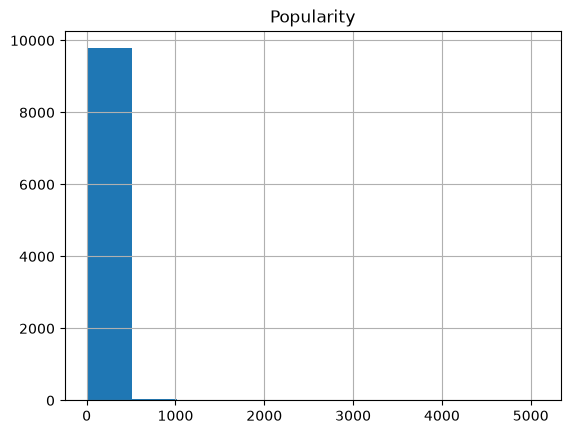

In [12]:
df_clean.hist('Popularity')

In [13]:
# note all data exploretion info

#1.All col have missing value
#2. convert data type release_Date(str) to datetime formate
#3. convert vote_count and vote_avg to float data type
#4. No duplicated col & drop Original_Language and Poster_Ur because dose not nees solve this question 
#5. Work numerical col after conver all col to numeric
#6. convert all col name to lower case 
#7.separet all Genre 
#8. realtion between popularity & vote_count & vote_avg


In [14]:
# start data cleaning 
df_clean.columns

Index(['Release_Date', 'Title', 'Overview', 'Popularity', 'Vote_Count',
       'Vote_Average', 'Original_Language', 'Genre', 'Poster_Url'],
      dtype='str')

In [15]:
# Convert data types

df_clean['Release_Date'] = pd.to_datetime(
    df_clean['Release_Date'],
    errors='coerce'
)

df_clean['Vote_Count'] = pd.to_numeric(
    df_clean['Vote_Count'],
    errors='coerce'
)

df_clean['Vote_Average'] = pd.to_numeric(
    df_clean['Vote_Average'],
    errors='coerce'
)

In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Release_Date       9827 non-null   datetime64[us]
 1   Title              9828 non-null   str           
 2   Overview           9828 non-null   str           
 3   Popularity         9827 non-null   float64       
 4   Vote_Count         9826 non-null   float64       
 5   Vote_Average       9826 non-null   float64       
 6   Original_Language  9827 non-null   str           
 7   Genre              9826 non-null   str           
 8   Poster_Url         9826 non-null   str           
dtypes: datetime64[us](1), float64(3), str(5)
memory usage: 4.4 MB


In [17]:
# Drop all null col
#df_clean[df_clean.isnull().any(axis=1)]
df_clean = df_clean.dropna()

In [18]:
df_clean.isnull().sum()
df_clean.info()

<class 'pandas.DataFrame'>
Index: 9826 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Release_Date       9826 non-null   datetime64[us]
 1   Title              9826 non-null   str           
 2   Overview           9826 non-null   str           
 3   Popularity         9826 non-null   float64       
 4   Vote_Count         9826 non-null   float64       
 5   Vote_Average       9826 non-null   float64       
 6   Original_Language  9826 non-null   str           
 7   Genre              9826 non-null   str           
 8   Poster_Url         9826 non-null   str           
dtypes: datetime64[us](1), float64(3), str(5)
memory usage: 4.4 MB


In [19]:
# drop sum col

df_clean =df_clean.drop(columns=['Overview','Poster_Url'])

In [20]:
# some Genre oparation 
all_genre = (

    df_clean['Genre'].dropna().str.split(', ').explode()
)
genre_counts = all_genre.value_counts()
print("Most frequent genre:", genre_counts.index[0])
print("Movie genre count:", genre_counts.iloc[0])

Most frequent genre: Drama
Movie genre count: 3744


In [21]:
df_clean['Genre'].head()

0    Action, Adventure, Science Fiction
1              Crime, Mystery, Thriller
2                              Thriller
3    Animation, Comedy, Family, Fantasy
4      Action, Adventure, Thriller, War
Name: Genre, dtype: str

In [22]:
def catigorize_col (df, col, labels):
    edges = [df[col].describe()['min'],
             df[col].describe()['25%'],
             df[col].describe()['50%'],
             df[col].describe()['75%'],
             df[col].describe()['max']
            ]

    df[col]=pd.cut(df[col],edges, labels = labels, duplicates = 'drop')
    return df;

In [23]:
labels = ['popular', 'below_avg', 'average','not_popular']
catigorize_col(df_clean,'Vote_Average',labels)
df_clean['Vote_Average'].unique()

['not_popular', 'below_avg', 'average', 'popular', NaN]
Categories (4, str): ['popular' < 'below_avg' < 'average' < 'not_popular']

In [24]:
# convert all datetime to a single year
df_clean['Release_Date']=df_clean['Release_Date'].dt.year


In [25]:
df_clean['Release_Date'].dtypes

dtype('int32')

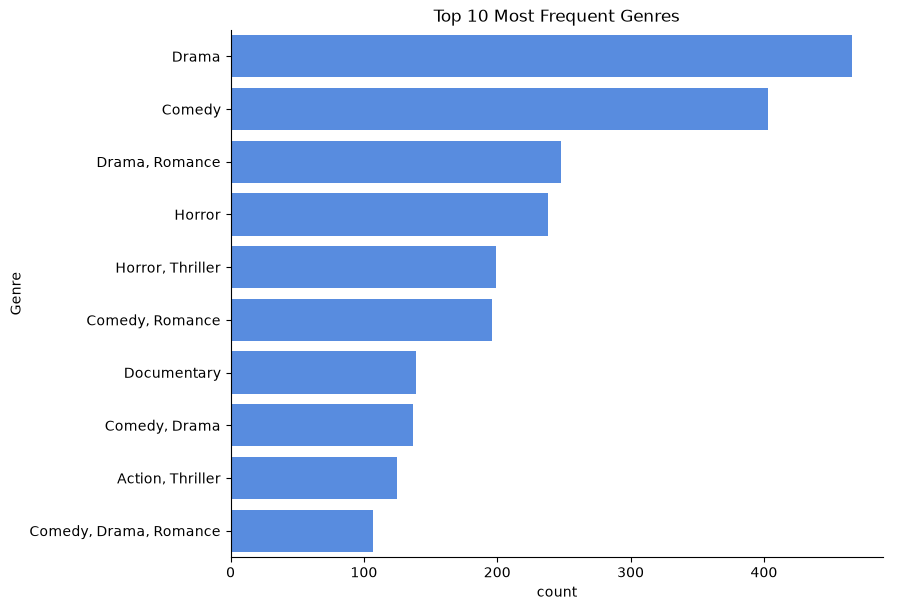

In [26]:
sns.catplot(
    y='Genre',
    data=df_clean,
    kind='count',
    order=df_clean['Genre'].value_counts().head(10).index,
    color='#4287f5',
    height=6,
    aspect=1.5
)

plt.title('Top 10 Most Frequent Genres')
plt.show()

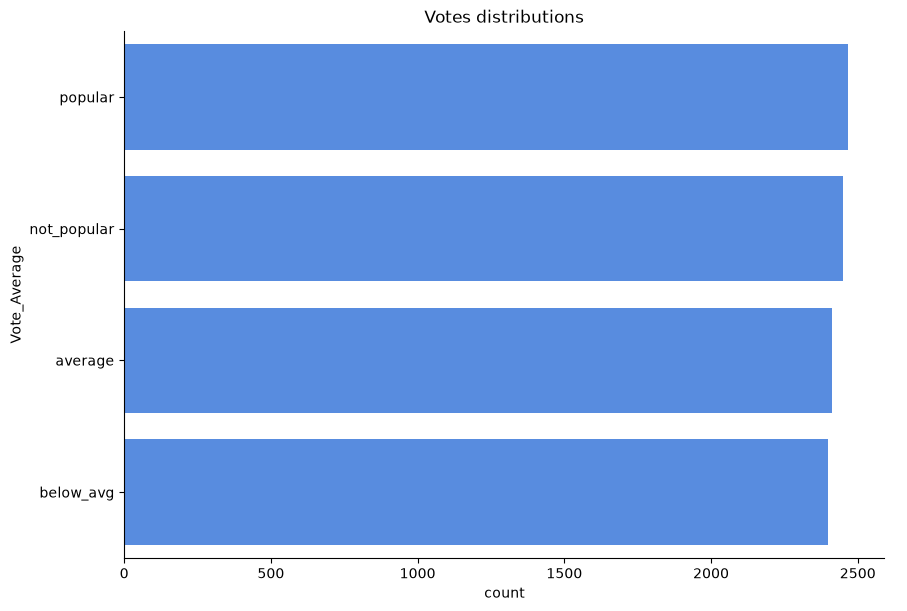

In [28]:
#what genre has hight votes
sns.catplot(
    y='Vote_Average',
    data=df_clean,
    kind='count',
    order=df_clean['Vote_Average'].value_counts().index,
    color='#4287f5',
    height=6,
    aspect=1.5
)

plt.title('Votes distributions')
plt.show()

In [33]:
# what movie got the highest popularity ? what's it's 
df_clean[df_clean['Popularity'] == df_clean['Popularity'].max()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Original_Language,Genre
0,2021,Spider-Man: No Way Home,5083.954,8940.0,not_popular,en,"Action, Adventure, Science Fiction"


In [34]:
# what movie got the min popularity ? what's it's 
df_clean[df_clean['Popularity'] == df_clean['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Original_Language,Genre
9835,2021,The United States vs. Billie Holiday,13.354,152.0,average,en,"Music, Drama, History"
9836,1984,Threads,13.354,186.0,not_popular,en,"War, Drama, Science Fiction"


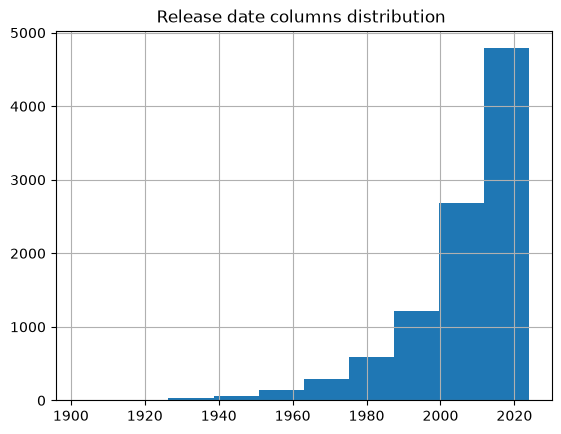

In [36]:
#5. Which year has the most filmmed movies ? 
df_clean['Release_Date'].hist()
plt.title('Release date columns distribution ')
plt.show()

In [37]:
df_clean.to_csv("mymoviedb_cleaned.csv", index=False)